In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"D:\RNW\supervised learning\project 3(Risk Alert Classifier)\Risk_Alert_Classifier_Dataset_4600 - Risk_Alert_Classifier_Dataset_4600.csv.csv")
df.head()


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [3]:
df.describe(include="all")

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
count,4600.000000,4460.000000,4600,4498,4456,4434.000000,4384.000000,4453.000000,4600.000000,4600.000000,4600.000000,4471.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600,4600.000000,4600.000000
unique,NaN,NaN,3,5,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90,NaN,NaN
top,NaN,NaN,Male,South,Salaried,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-09-12,NaN,NaN
freq,NaN,NaN,2358,1057,2354,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66,NaN,NaN
mean,502300.500000,36.360314,NaN,NaN,NaN,41753.518268,677.784443,0.394721,0.924130,5.538696,65.030000,21511.273541,0.709783,0.443478,2.087174,53.744565,NaN,41143.328696,0.121087
std,1328.049949,10.670375,NaN,NaN,NaN,17740.750972,64.888787,0.205771,1.300018,5.624891,24.180762,10887.272864,1.020507,0.716546,1.621504,31.325334,NaN,26665.221097,0.326264
min,500001.000000,18.000000,NaN,NaN,NaN,15000.000000,405.000000,0.002000,0.000000,0.100000,5.000000,3769.000000,0.000000,0.000000,0.000000,2.000000,NaN,3653.000000,0.000000
25%,501150.750000,28.000000,NaN,NaN,NaN,28980.000000,638.000000,0.232000,0.000000,2.100000,49.000000,13422.500000,0.000000,0.000000,1.000000,31.000000,NaN,21302.750000,0.000000
50%,502300.500000,36.000000,NaN,NaN,NaN,38932.500000,682.000000,0.370000,1.000000,3.900000,65.000000,19317.000000,0.000000,0.000000,2.000000,48.000000,NaN,35638.500000,0.000000
75%,503450.250000,44.000000,NaN,NaN,NaN,51282.500000,721.250000,0.531000,1.000000,6.600000,81.000000,27147.000000,1.000000,1.000000,3.000000,70.000000,NaN,54274.250000,0.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

In [5]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (4600, 19)


## Handle Missing Value

In [6]:
missing_val = df.isna().sum()
missing_val_percentage = df.isna().sum() / len(df)*100
missing_summary = pd.DataFrame({
    "missing_val":missing_val,
    "missing_val_percentage":missing_val_percentage
})
missing_summary = missing_summary[missing_val > 0].sort_values("missing_val", ascending=False)
missing_summary

,missing_val,missing_val_percentage
credit_score,216,4.695652
annual_income_inr,166,3.608696
credit_utilization_ratio,147,3.195652
employment_type,144,3.130435
age,140,3.043478
monthly_spend_inr,129,2.804348
region,102,2.217391


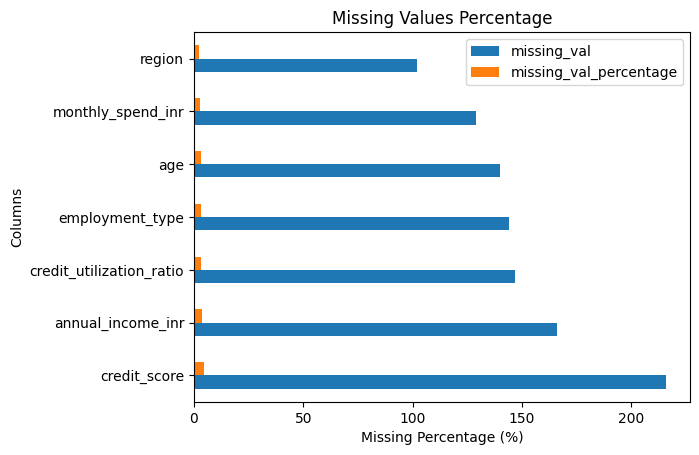

In [7]:
missing_summary.plot(kind = "barh")
plt.title("Missing Values Percentage")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Columns")
plt.show()

In [8]:
df["risk_status"].value_counts(normalize=True)*100

risk_status
0    87.891304
1    12.108696
Name: proportion, dtype: float64

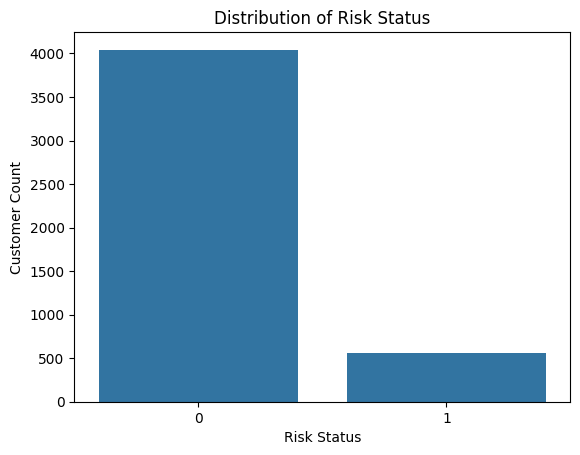

In [9]:
sns.countplot(df, x = "risk_status")
plt.title("Distribution of Risk Status")
plt.xlabel("Risk Status")
plt.ylabel("Customer Count")
plt.show()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
from sklearn.impute import SimpleImputer, KNNImputer

In [12]:
null_num_col = ["credit_score", "annual_income_inr", "credit_utilization_ratio", "age", "monthly_spend_inr"]
null_cat_col = ["employment_type", "region",]

In [13]:
knn_imput = KNNImputer(n_neighbors = 5)
df[null_num_col] = knn_imput.fit_transform(df[null_num_col])

In [14]:
si_imput = SimpleImputer(strategy="most_frequent")
df[null_cat_col] = si_imput.fit_transform(df[null_cat_col])

## Feature Extraction

In [15]:
df["last_transaction_date"] = pd.to_datetime(df["last_transaction_date"])
df["last_transaction_day"] = df["last_transaction_date"].dt.day
df["last_transaction_month"] = df["last_transaction_date"].dt.month
df["last_transaction_year"] = df["last_transaction_date"].dt.year
df.drop(columns=["customer_id", "last_transaction_date"], errors="coerce", inplace=True)

In [16]:

num_col = df.select_dtypes(include=["int", "float"]).columns.drop(
    "risk_status", errors="ignore"
)


In [17]:
cat_col = df.select_dtypes(include=["object", "category"]).columns

## Handle Outliers

In [18]:
for col in num_col:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    df[col] = df[col].clip(lower_bound, upper_bound)

In [19]:
df["gender"] = df["gender"].map({
    "Male":0,
    "Female":1,
    "Other":2
})

In [20]:
df["employment_type"].value_counts()

employment_type
Salaried         2498
Self-Employed    1133
Student           393
Unemployed        355
Retired           221
Name: count, dtype: int64

In [21]:
from sklearn.preprocessing import OneHotEncoder
oe = OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop = "first")
encode = oe.fit_transform(df[["employment_type", "region"]])

encoded_df = pd.DataFrame(
    encode,
    columns = oe.get_feature_names_out(),
    index = df.index
)
df = pd.concat(
    [df.drop(columns=["employment_type","region"]), encoded_df],
    axis=1
)


In [22]:
df[num_col].skew().sort_values(ascending=False)

complaints_last_6m           1.349796
avg_late_payment_days        1.028498
cash_advance_count_6m        0.955280
debt_balance_inr             0.833213
monthly_spend_inr            0.801483
missed_payments_12m          0.734990
account_tenure_months        0.732115
failed_login_attempts_3m     0.677123
annual_income_inr            0.643749
credit_utilization_ratio     0.451276
age                          0.205588
last_transaction_month       0.023442
monthly_transaction_count    0.006541
last_transaction_year        0.000000
last_transaction_day        -0.022860
credit_score                -0.215568
dtype: float64

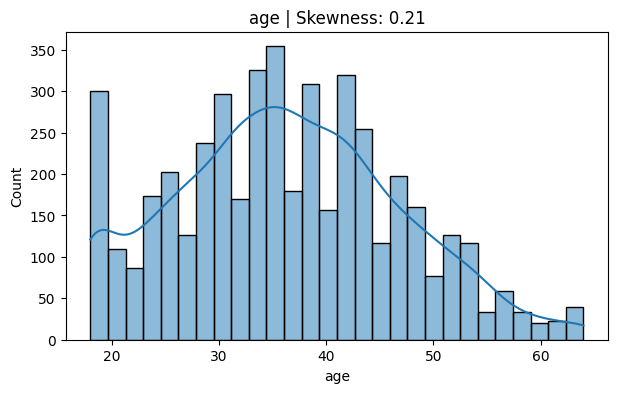

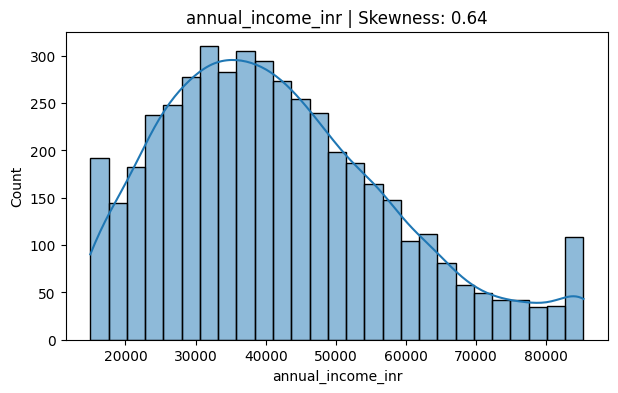

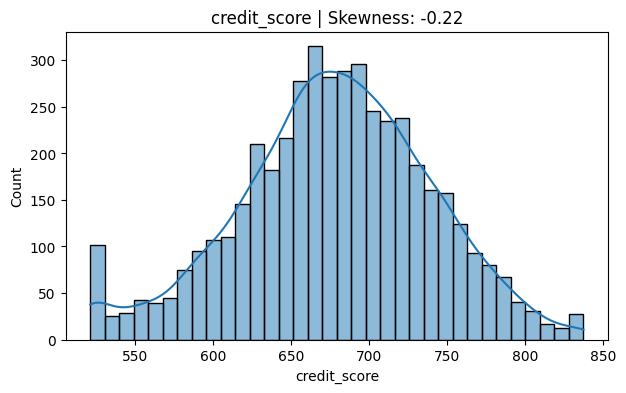

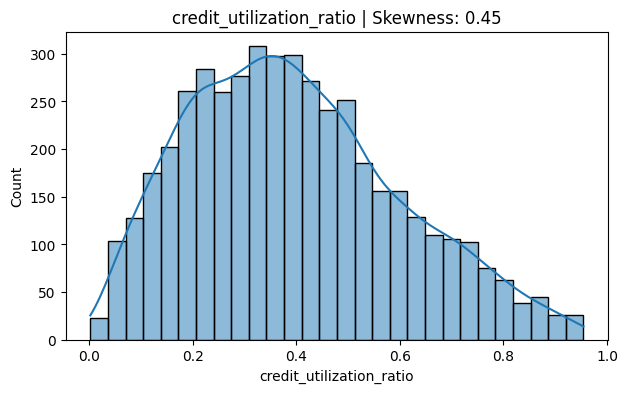

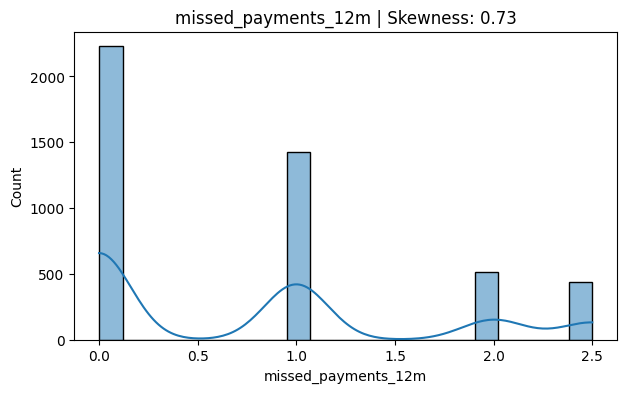

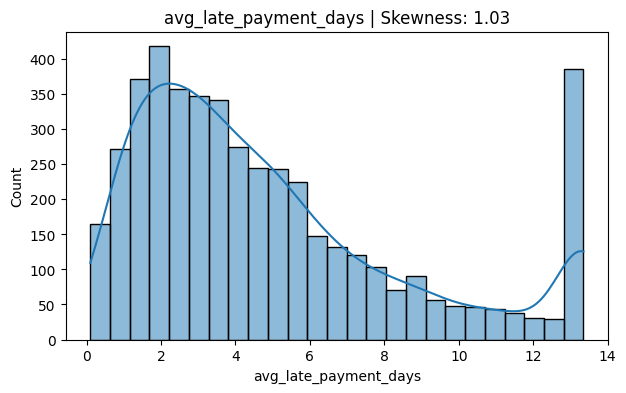

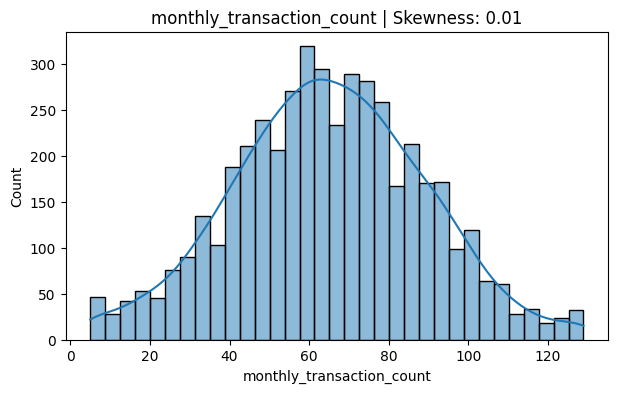

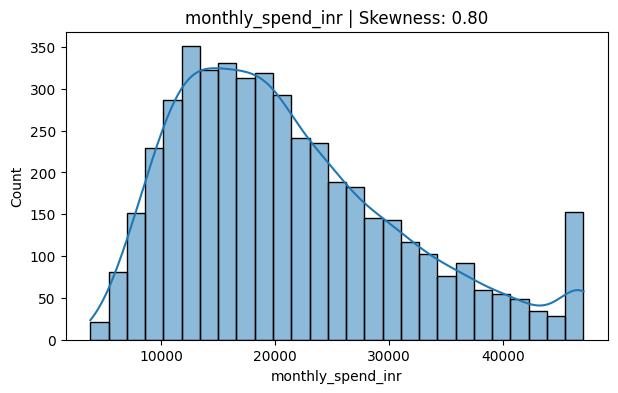

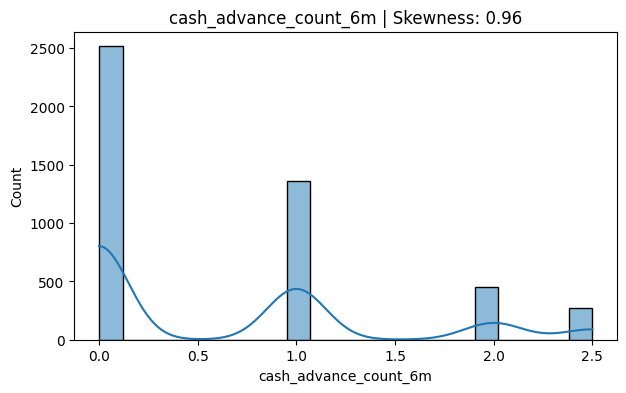

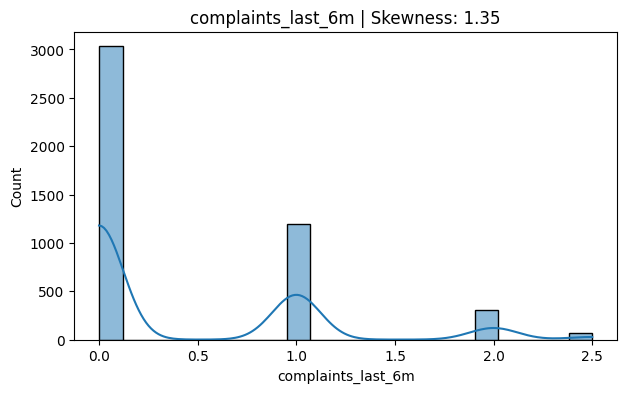

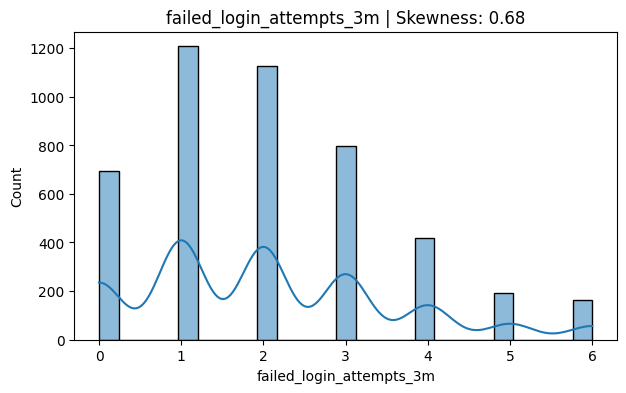

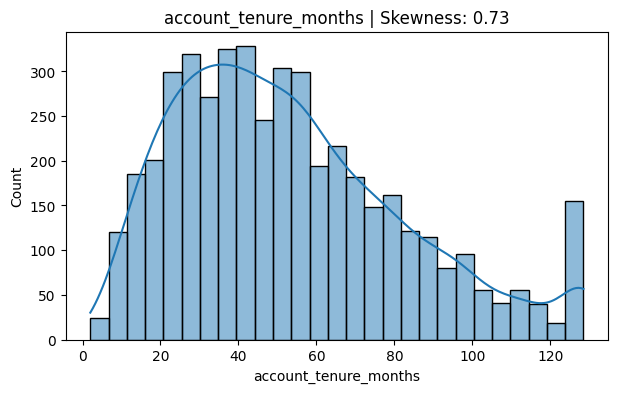

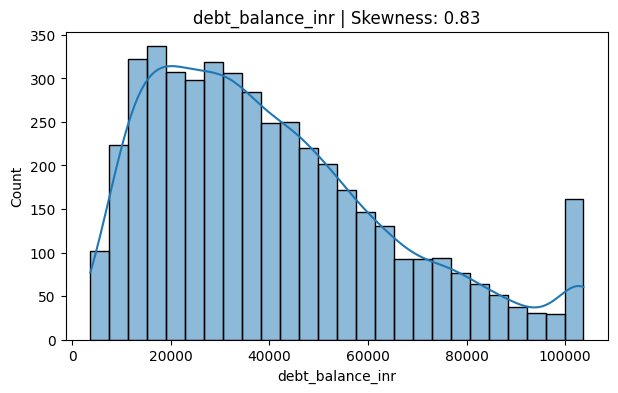

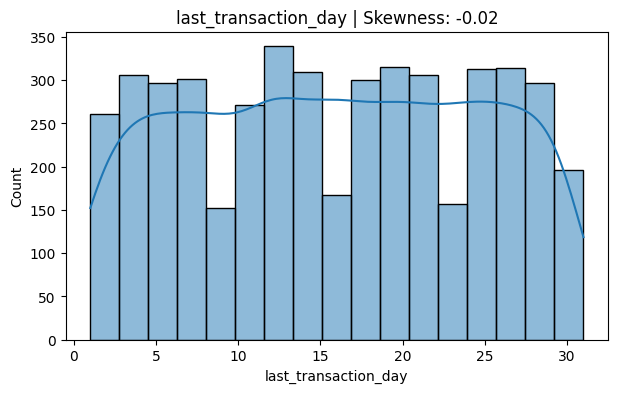

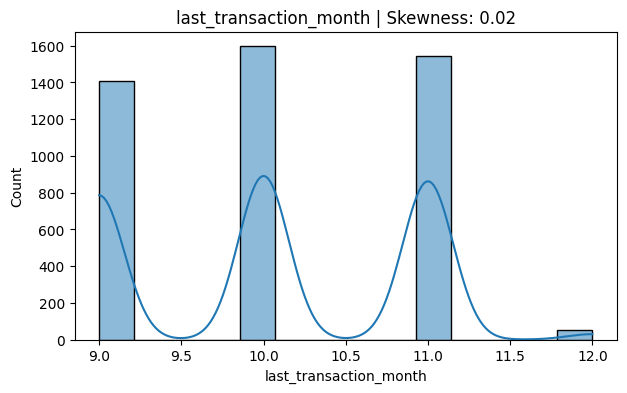

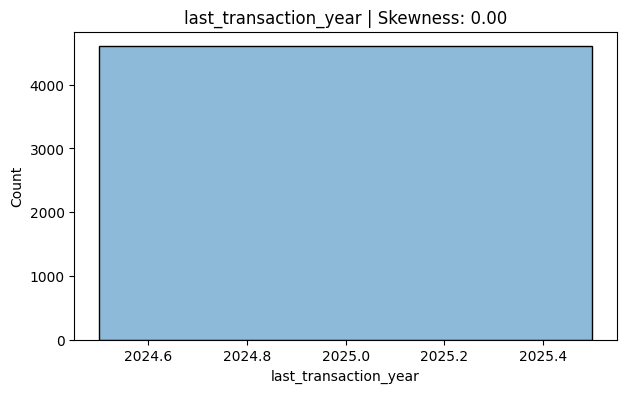

In [23]:
for col in num_col:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"{col} | Skewness: {df[col].skew():.2f}")
    plt.show()

In [24]:
skew_col = ["annual_income_inr", "missed_payments_12m", "avg_late_payment_days", "monthly_spend_inr", "cash_advance_count_6m", "complaints_last_6m",
"failed_login_attempts_3m", "account_tenure_months", "debt_balance_inr", ]

In [25]:
from sklearn.preprocessing import PowerTransformer

In [26]:
pt = PowerTransformer(method="yeo-johnson")
df[skew_col] = pt.fit_transform(df[skew_col])

In [27]:
df[skew_col].skew()

annual_income_inr          -0.017450
missed_payments_12m         0.167656
avg_late_payment_days       0.000126
monthly_spend_inr          -0.013479
cash_advance_count_6m       0.308291
complaints_last_6m          0.688587
failed_login_attempts_3m   -0.040873
account_tenure_months      -0.035211
debt_balance_inr           -0.041087
dtype: float64

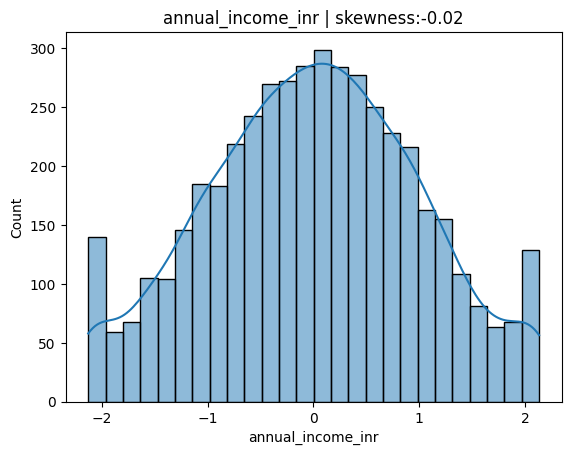

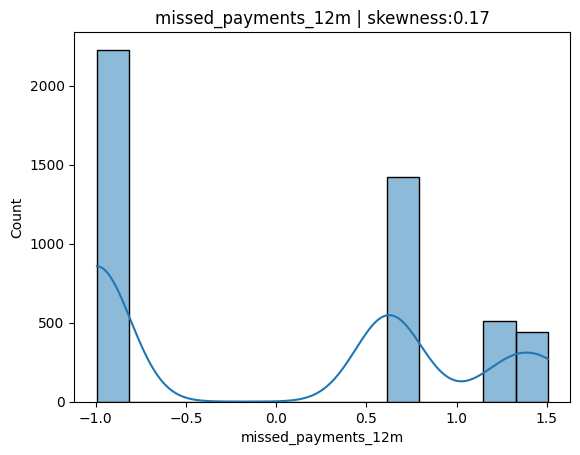

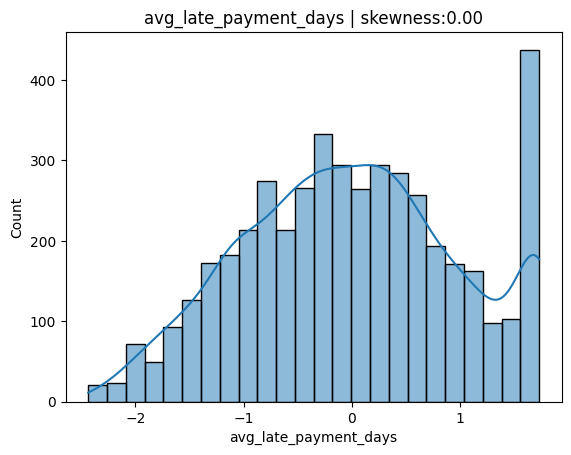

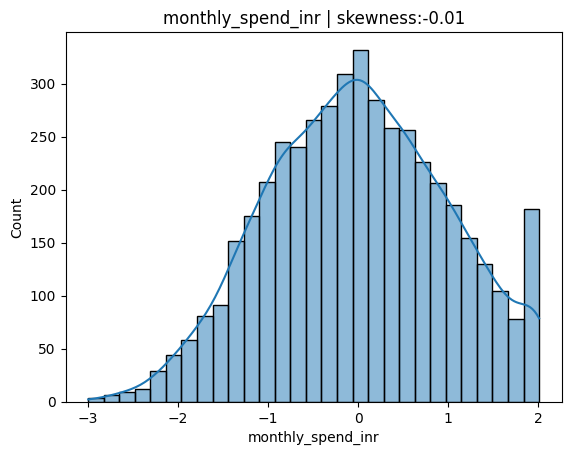

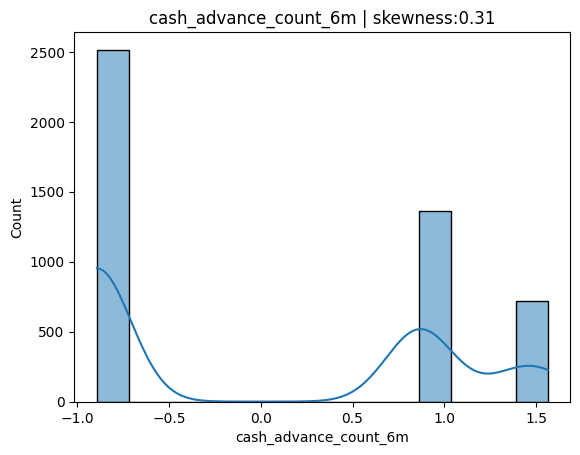

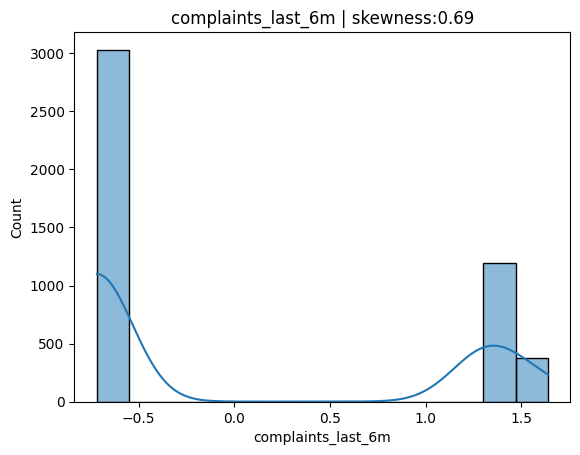

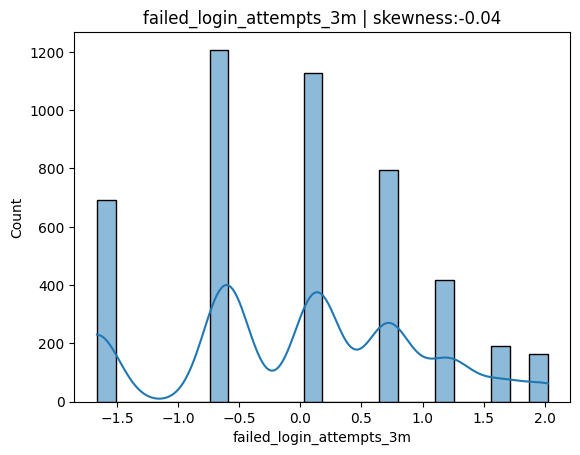

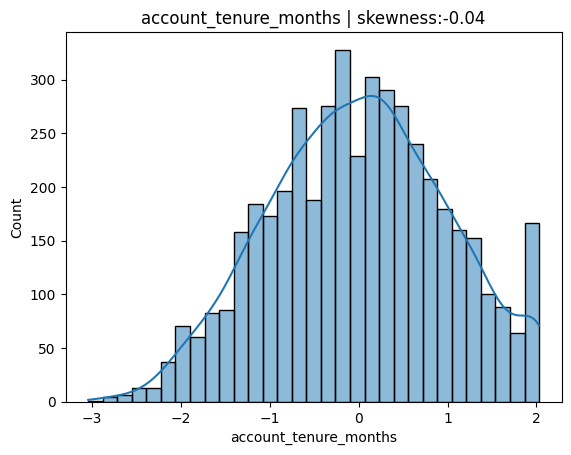

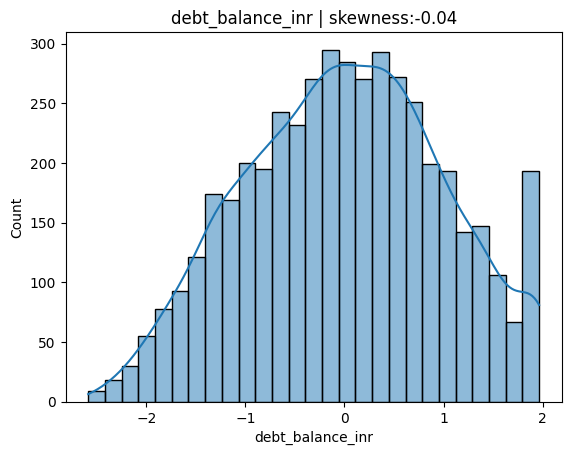

In [28]:
for col in skew_col:
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"{col} | skewness:{df[col].skew():.2f}")
    plt.show()

In [30]:
df["risk_status"].value_counts()

risk_status
0    4043
1     557
Name: count, dtype: int64

In [32]:
x = df.drop(columns='risk_status')
y = df['risk_status']

In [33]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=32,
    stratify=y
)

In [34]:
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (3680, 25)
x_test: (920, 25)
y_train: (3680,)
y_test: (920,)


In [36]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_sclae = scaler.fit_transform(x_train)
x_test_scale = scaler.transform(x_test)

print("x_train_scale shape:", x_train_sclae.shape)
print("x_test_sclae shape:", x_test_scale.shape)

x_train_scale shape: (3680, 25)
x_test_sclae shape: (920, 25)


In [37]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(x_train_sclae, y_train)

print("Model Train Successfully")

Model Train Successfully


In [41]:
y_pred = lr.predict(x_test_scale)
print(y_pred[:10])

[0 0 0 0 0 0 1 0 0 0]


In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9934782608695653
Precision: 0.981651376146789
Recall: 0.963963963963964
F1 Score: 0.9727272727272728

Confusion Matrix:
[[807   2]
 [  4 107]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.98      0.96      0.97       111

    accuracy                           0.99       920
   macro avg       0.99      0.98      0.98       920
weighted avg       0.99      0.99      0.99       920



In [66]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from sklearn.linear_model import LogisticRegression


In [67]:
under_sampler = RandomUnderSampler(random_state=32)
x_under, y_under = under_sampler.fit_resample(
    x_train_sclae, y_train
)

lr_under = LogisticRegression(max_iter=1000)
lr_under.fit(x_under, y_under)

pred_under = lr_under.predict(x_test_scale)

print("Accuracy:", accuracy_score(y_test, pred_under))
print("Precison:", precision_score(y_test, pred_under))
print("f1_score:", f1_score(y_test, pred_under))
print("Recall:", recall_score(y_test, pred_under))

Accuracy: 0.9815217391304348
Precison: 0.873015873015873
f1_score: 0.9282700421940928
Recall: 0.990990990990991


In [68]:
over_sampler = RandomOverSampler(random_state=32)
x_over, y_over = over_sampler.fit_resample(
    x_train_sclae, y_train
)
lr_over = LogisticRegression(max_iter=1000)

lr_over.fit(x_over, y_over)
pred_over = lr_over.predict(x_test_scale)

print("Accuracy:", accuracy_score(y_test, pred_over))
print("Precision:", precision_score(y_test, pred_over))
print("f1_score:", f1_score(y_test, pred_over))
print("Recall:", recall_score(y_test, pred_over))

Accuracy: 0.9880434782608696
Precision: 0.923728813559322
f1_score: 0.9519650655021834
Recall: 0.9819819819819819


In [69]:
smote = SMOTE(random_state=32)
x_smote, y_smote = smote.fit_resample(
    x_train_sclae, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_smote.value_counts())

lr_smote = LogisticRegression(max_iter=1000)

lr_smote.fit(x_smote, y_smote)

pred_smote = lr_smote.predict(x_test_scale)
print("Accuracy:", accuracy_score(y_test, pred_smote))
print("Precision:", precision_score(y_test, pred_smote))
print("f1_score:", f1_score(y_test, pred_smote))
print("Recall:", recall_score(y_test, pred_smote))

Before SMOTE:
risk_status
0    3234
1     446
Name: count, dtype: int64

After SMOTE:
risk_status
0    3234
1    3234
Name: count, dtype: int64
Accuracy: 0.9902173913043478
Precision: 0.9473684210526315
f1_score: 0.96
Recall: 0.972972972972973


In [70]:
from sklearn.metrics import recall_score, f1_score, roc_auc_score
import pandas as pd


pred_original = lr.predict(x_test_scale)
prob_original = lr.predict_proba(x_test_scale)[:, 1]


pred_over = lr_over.predict(x_test_scale)
prob_over = lr_over.predict_proba(x_test_scale)[:, 1]

pred_smote = lr_smote.predict(x_test_scale)
prob_smote = lr_smote.predict_proba(x_test_scale)[:, 1]

results = pd.DataFrame({
    "Model": ["Before Balancing", "Over-Sampling", "SMOTE"],
    "Minority Recall": [
        recall_score(y_test, pred_original, pos_label=1, zero_division=0),
        recall_score(y_test, pred_over, pos_label=1, zero_division=0),
        recall_score(y_test, pred_smote, pos_label=1, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, pred_original, pos_label=1, zero_division=0),
        f1_score(y_test, pred_over, pos_label=1, zero_division=0),
        f1_score(y_test, pred_smote, pos_label=1, zero_division=0)
    ],
    "AUC-ROC": [
        roc_auc_score(y_test, prob_original),
        roc_auc_score(y_test, prob_over),
        roc_auc_score(y_test, prob_smote)
    ]
})

results.round(4)

,Model,Minority Recall,F1-Score,AUC-ROC
0,Before Balancing,0.964,0.9727,0.9994
1,Over-Sampling,0.982,0.9520,0.9992
2,SMOTE,0.973,0.9600,0.9994


In [72]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=32,
    class_weight="balanced"
)

dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)
y_prob_dt = dt_model.predict_proba(x_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dt, zero_division=0))
print("F1-Score:", f1_score(y_test, y_pred_dt, zero_division=0))
print("AUC-ROC:", roc_auc_score(y_test, y_prob_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Accuracy: 0.9608695652173913
Precision: 0.831858407079646
Recall: 0.8468468468468469
F1-Score: 0.8392857142857143
AUC-ROC: 0.9116805309635965

Confusion Matrix:
[[790  19]
 [ 17  94]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       809
           1       0.83      0.85      0.84       111

    accuracy                           0.96       920
   macro avg       0.91      0.91      0.91       920
weighted avg       0.96      0.96      0.96       920



In [74]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=32,
    n_jobs=-1
)

rf_model.fit(x_train, y_train)
rf_predict = rf_model.predict(x_test)

y_prob_rf = rf_model.predict_proba(x_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, rf_predict))
print("Precision:", precision_score(y_test, rf_predict, zero_division=0))
print("Recall:", recall_score(y_test, rf_predict, zero_division=0))
print("F1-Score:", f1_score(y_test, rf_predict, zero_division=0))
print("AUC-ROC:", roc_auc_score(y_test, rf_predict))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predict))

print("\nClassification Report:")
print(classification_report(y_test,rf_predict, zero_division=0))

Accuracy: 0.9847826086956522
Precision: 0.9801980198019802
Recall: 0.8918918918918919
F1-Score: 0.9339622641509434
AUC-ROC: 0.9447098520028062

Confusion Matrix:
[[807   2]
 [ 12  99]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       809
           1       0.98      0.89      0.93       111

    accuracy                           0.98       920
   macro avg       0.98      0.94      0.96       920
weighted avg       0.98      0.98      0.98       920



In [75]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train F1-Score": f1_score(y_train, train_pred, zero_division=0),
        "Test F1-Score": f1_score(y_test, test_pred, zero_division=0),
        "Accuracy Gap": (
            accuracy_score(y_train, train_pred)
            - accuracy_score(y_test, test_pred)
        )
    })

comparison_df = pd.DataFrame(results)
comparison_df.round(4)

,Model,Train Accuracy,Test Accuracy,Train F1-Score,Test F1-Score,Accuracy Gap
0,Decision Tree,1.0,0.9609,1.0,0.8393,0.0391
1,Random Forest,1.0,0.9848,1.0,0.9340,0.0152


In [77]:
from sklearn.model_selection import RandomizedSearchCV
dt_params = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy", "log_loss"],
    "class_weight": ["balanced", None]
}

dt_random = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=32),
    param_distributions=dt_params,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=32,
    n_jobs=-1,
    verbose=1
)

dt_random.fit(x_train, y_train)

print("Best Decision Tree Parameters:")
print(dt_random.best_params_)

print("Best CV F1-Score:", dt_random.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Decision Tree Parameters:
{'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 10, 'criterion': 'log_loss', 'class_weight': None}
Best CV F1-Score: 0.9048800585242567


In [78]:
rf_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", None],
    "class_weight": ["balanced", "balanced_subsample", None]
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=32,
        n_jobs=1
    ),
    param_distributions=rf_params,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=32,
    n_jobs=-1,
    verbose=1
)

rf_random.fit(x_train, y_train)

print("Best Random Forest Parameters:")
print(rf_random.best_params_)

print("Best CV F1-Score:", rf_random.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Random Forest Parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced_subsample'}
Best CV F1-Score: 0.9725419341497894


In [79]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Parameter grid for fine-tuning
rf_grid_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced", None]
}

# Create Grid Search
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=32,
        n_jobs=1
    ),
    param_grid=rf_grid_params,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train using training data
rf_grid.fit(x_train, y_train)

print("Best Parameters:")
print(rf_grid.best_params_)

print("Best Cross-Validation F1-Score:")
print(rf_grid.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Parameters:
{'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Best Cross-Validation F1-Score:
0.9701493437470552


In [84]:
from sklearn.metrics import roc_auc_score

print("Logistic Regression:",
      roc_auc_score(y_test, lr.predict_proba(x_test_scale)[:, 1]))

print("Decision Tree:",
      roc_auc_score(y_test, dt_model.predict_proba(x_test)[:, 1]))

print("Random Forest:",
      roc_auc_score(y_test, rf_model.predict_proba(x_test)[:, 1]))

Logistic Regression: 0.9994432009265136
Decision Tree: 0.9116805309635965
Random Forest: 0.9974554282341674


In [86]:
from sklearn.metrics import confusion_matrix

models = {
    "Logistic Regression": (lr, x_test_scale),
    "Decision Tree": (dt_model, x_test),
    "Random Forest": (rf_model, x_test)
}

for name, (model, X) in models.items():
    y_pred = model.predict(X)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(name, "False Negatives:", fn)

Logistic Regression False Negatives: 4
Decision Tree False Negatives: 17
Random Forest False Negatives: 12
